# Import

In [2]:
%reset -f
import tensorflow as tf
import numpy as np
from time import time
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

2022-09-07 12:40:48.136447: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:936] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-09-07 12:40:48.153526: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudnn.so.8'; dlerror: libcudnn.so.8: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/run/user/1000/doc:/run/user/1000/doc
2022-09-07 12:40:48.153538: W tensorflow/core/common_runtime/gpu/gpu_device.cc:1850] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
2022-09-07 12:40:48.153946: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is 

# generate training data

In [3]:
# Set boundary
tmin = 0.
tmax = 1.5
xmin = 0.
xmax = 1.
ymin = 0. 
ymax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin, ymin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax, ymax], dtype=DTYPE)

In [4]:
X_r, X_data, u_data = gen_train_data(lb, ub, 100_000,40_000,15_000)

In [5]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=8, num_neurons_per_layer=128, activation='tanh')
solver = PINNSolver(model, batch_size = 10_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=200,
    decay_rate=0.98,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, X_data, u_data, alpha = 0.2)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 00_000: phi_r  3.8026e+00    phi_0  1.2999e+00    phi_b  1.5118e+00    total_loss  6.6143e+00
Training time: 28.164806842803955 seconds


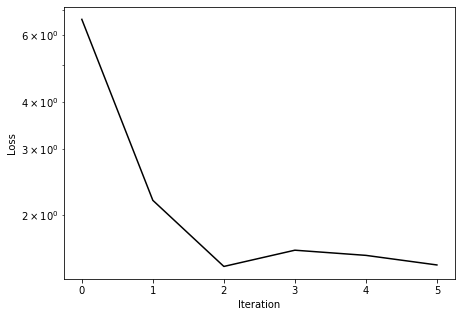

In [6]:
solver.plot_loss_history();

# vérification que ca fonctionne 

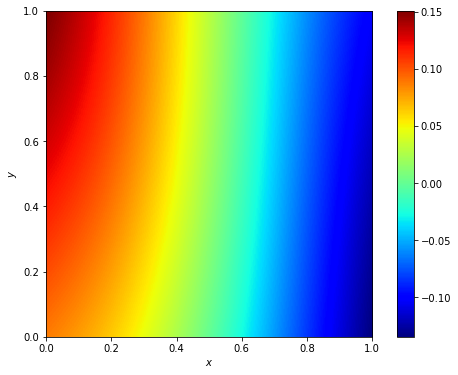

In [7]:
#model.load_weights('saved_models/best_weight-hubert.h5')

N = 150

# compute solution using PINN
xspace = np.linspace(0,1,N)
yspace = np.linspace(0,1,N)
tfinal =  1.5 * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

# reshape for plotting
U = upred.numpy().reshape(N,N)

# plot solution
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')  
img = ax.imshow(U, cmap='jet', origin='lower', extent=[0.,1.,0.,1.]);
fig.colorbar(img);